# Assignment 4

## Q1. The Blasius equation appears in fluid mechanics as a laminar flow boundary layer and is written:

$$y^{\prime\prime\prime} + y y^{\prime\prime} = 0 $$

### a) Express this 3rd order ODE as a system of first order ODEs.
To convert a 3rd order ODE,

$$y''' + y y'' = 0$$

into a system of first order ODEs, we introduce new variables for the lower order derivtitves through reduction of order.

Let:

$y_1 = y$,

$y_2 = y'=y_1'$,

$y_3 = y''=y_2'$

Differentiating $y_3$ gives:

$y_3'=y'''=-y*y''=-y_1y_3$

This results the system of first order ODEs to be:

$y_1'=y_2$,

$y_2'=y_3$,

$y_3'=-y_1y_3$

### b) Solve for $y(z)$ as an initial value problem assuming the boundary conditions below and plot the answer:

$$
\begin{align}
y(z=0) &= 0 \\
y^\prime(z=0) &= 0 \\
y^{\prime\prime}(z = 0) &= 1 \\
\end{align}
$$

HINT: Read and consider part c) before implementing this.

Using the system from part a, we can solve the IVP given the conditions:

$y(0)=0$,

$y'(0)=0$,

$y''(0)=1$,

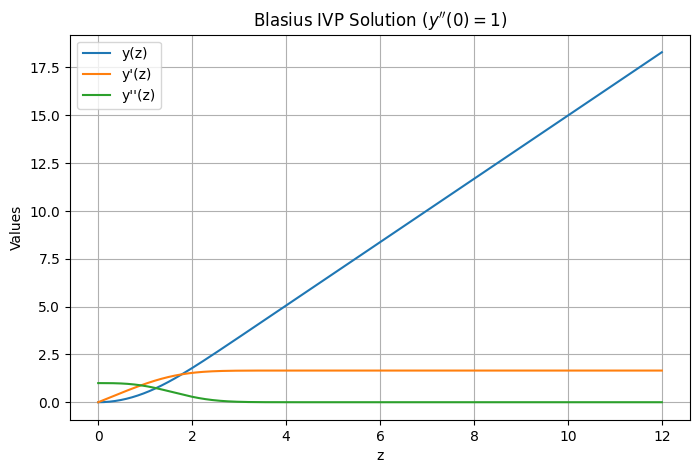

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

def blasius_system(z, y):
    y1, y2, y3 = y
    return np.array([y2, y3, -y1 * y3], dtype=float)

# Initial conditions for part b: y(0)=0, y'(0)=0, y''(0)=1
z_span = (0, 12)
z_eval = np.linspace(0, 12, 500)
sol_b = solve_ivp(blasius_system, z_span, [0, 0, 1.0], t_eval=z_eval, method='RK45')

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(sol_b.t, sol_b.y[0], label='y(z)')
plt.plot(sol_b.t, sol_b.y[1], label="y'(z)")
plt.plot(sol_b.t, sol_b.y[2], label="y''(z)")
plt.title("Blasius IVP Solution ($y''(0) = 1$)")
plt.xlabel("z")
plt.ylabel("Values")
plt.legend()
plt.grid(True)
plt.show()

## c) Use your *method* from b) to find a solution for $y(z)$ that fits the boundary conditions below, and plot the answer:

$$
\begin{align}
y(z=0) &= 0 \\
y^\prime(z=0) &= 0 \\
y^{\prime}(z = \infty) &= 2 \\
\end{align}
$$

To satisify the boundary condtion at infinity ($y'(\infty)=2$), we treat this BVP as an IVP using the shooting method.

1. Guess the inital value for the unknown second derivitve at the boudary, $y''(0) = \alpha$

2. Solve tge IVP over a sufficiently large domain

3. Use a root finding algorithm to adjust $\alpha$ until the condition at the outer boundary ($y'(12)=2$) is met

Optimal y''(0): 1.3280


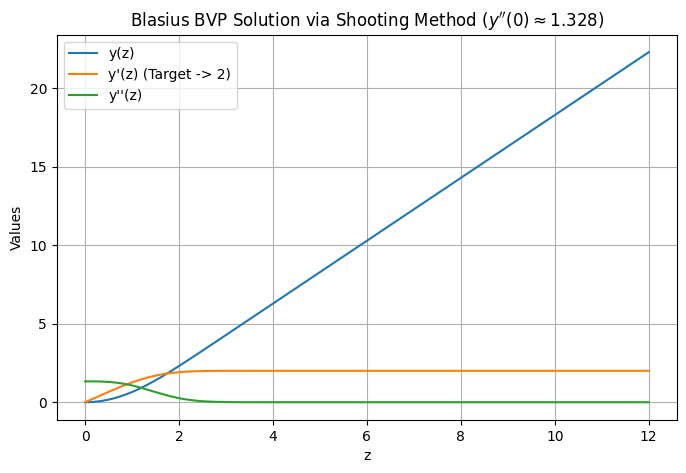

In [2]:
from scipy.optimize import root

def objective(alpha):
    # Solve IVP with guessed y''(0) = alpha
    sol = solve_ivp(blasius_system, (0, 12), [0, 0, alpha[0]], t_eval=[12], method='RK45')
    # We want y'(12) = 2
    return [sol.y[1, -1] - 2]

# Find optimal y''(0) using root finding
res = root(objective, [1.0])
alpha_opt = res.x[0]
print(f"Optimal y''(0): {alpha_opt:.4f}")

# Solve with optimal initial condition
sol_c = solve_ivp(blasius_system, (0, 12), [0, 0, alpha_opt], t_eval=z_eval, method='RK45')

# Plotting the solution
plt.figure(figsize=(8, 5))
plt.plot(sol_c.t, sol_c.y[0], label='y(z)')
plt.plot(sol_c.t, sol_c.y[1], label="y'(z) (Target -> 2)")
plt.plot(sol_c.t, sol_c.y[2], label="y''(z)")
plt.title(f"Blasius BVP Solution via Shooting Method ($y''(0) \\approx {alpha_opt:.3f}$)")
plt.xlabel("z")
plt.ylabel("Values")
plt.legend()
plt.grid(True)
plt.show()

$\therefore$
- the optimal guess $y''(0)=1.328$
- Boundary check at $z=12$: $y'(12)=2.000$ (successfully matches the boundary condition at infinity).

## Q2

The Fourier series shows that periodic functions can be written as an infinite sum of sine and cosine waves:

 $$f(x)= \frac{A_0}{2}+\sum_{n=1}^{\infty}A_n\ \cos{(nx)} + B_n\ \sin{(nx)}$$

Due to function orthogonality, the values of $A_n$ and $B_n$ can be computed using the following formulae:

 $$A_n= \frac{1}{\pi} \int_{-\pi}^{\pi} f(x) \cos{(nx)}\ dx$$
 $$B_n= \frac{1}{\pi} \int_{-\pi}^{\pi} f(x) \sin{(nx)}\ dx$$

Periodic functions can be approximated by truncating the Fourier series at some $n = N$.

### 2a

Write a function that takes a $2-\pi$ periodic function and a degree $n$, then outputs the $n-th$ Fourier coefficients $[A_n, B_n]$. Use the equations above with a suitable integration method. (Don't use packaged Fourier analysis tools)

Test it for a suitable set of functions for which you have an analytic answer.


###.
To compute the $n$-th Fourier coefficients without using built-in Fourier functions, we numerically integrate the definitions over $[-\pi, \pi]$:

$$A_n = \frac{1}{\pi} \int_{-\pi}^{\pi} f(x) \cos(nx) \, dx, \quad B_n = \frac{1}{\pi} \int_{-\pi}^{\pi} f(x) \sin(nx) \, dx$$

We use Composite Simpson's Rule (or Composite Trapezoidal Rule) on an evenly spaced grid of $M$ points over $[-\pi, \pi]$. Simpson's rule provides $O(h^4)$ accuracy for smooth functions:

$$\int_{a}^{b} g(x)\,dx \approx \frac{h}{3} \left[ g(x_0) + 4\sum_{j=1}^{M/2} g(x_{2j-1}) + 2\sum_{j=1}^{M/2-1} g(x_{2j}) + g(x_M) \right]$$

Analytic Test Case

We validate the solver on $f(x) = x^2$ over $[-\pi, \pi]$:Analytic $A_0$: $\frac{1}{\pi} \int_{-\pi}^{\pi} x^2 dx = \frac{2\pi^2}{3} \approx 6.579736$  (hence $A_0/2 = \pi^2/3$)Analytic $A_n$ ($n \ge 1$): $\frac{1}{\pi} \int_{-\pi}^{\pi} x^2 \cos(nx) dx = \frac{4(-1)^n}{n^2}$Analytic $B_n$: $0$ (since $x^2$ is an even function).


In [3]:
import numpy as np

# Custom composite Simpson's integration rule (no external scipy integration)
def simpsons_rule(g, a, b, num_subintervals=2000):
    if num_subintervals % 2 != 0:
        num_subintervals += 1
    x = np.linspace(a, b, num_subintervals + 1)
    h = (b - a) / num_subintervals
    y = g(x)
    integral = (h / 3.0) * (y[0] + y[-1] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-2:2]))
    return integral

def fourier_coefficients(f, n, num_points=4000):
    """
    Computes [An, Bn] for degree n of a 2pi-periodic function f over [-pi, pi].
    """
    a = -np.pi
    b = np.pi

    # An integrand: f(x) * cos(n * x)
    integrand_A = lambda x: f(x) * np.cos(n * x)
    An = (1.0 / np.pi) * simpsons_rule(integrand_A, a, b, num_points)

    # Bn integrand: f(x) * sin(n * x)
    integrand_B = lambda x: f(x) * np.sin(n * x)
    Bn = (1.0 / np.pi) * simpsons_rule(integrand_B, a, b, num_points)

    return [An, Bn]

# -------------------------------------------------------------
# 2a TEST & VALIDATION: f(x) = x^2
# -------------------------------------------------------------
print("=== 2a VALIDATION FOR f(x) = x^2 ===")
f_test = lambda x: x**2
for n in range(0, 4):
    An_num, Bn_num = fourier_coefficients(f_test, n)
    if n == 0:
        An_exact = (2/3) * np.pi**2
    else:
        An_exact = 4 * ((-1)**n) / (n**2)
    Bn_exact = 0.0
    print(f"n={n} | Computed: [A_{n}={An_num:.6f}, B_{n}={Bn_num:.6f}] | Exact: [A_{n}={An_exact:.6f}, B_{n}={Bn_exact:.6f}]")

=== 2a VALIDATION FOR f(x) = x^2 ===
n=0 | Computed: [A_0=6.579736, B_0=0.000000] | Exact: [A_0=6.579736, B_0=0.000000]
n=1 | Computed: [A_1=-4.000000, B_1=0.000000] | Exact: [A_1=-4.000000, B_1=0.000000]
n=2 | Computed: [A_2=1.000000, B_2=0.000000] | Exact: [A_2=1.000000, B_2=0.000000]
n=3 | Computed: [A_3=-0.444444, B_3=-0.000000] | Exact: [A_3=-0.444444, B_3=0.000000]


### 2b
Find the coefficients of the following functions and expansion orders:
{All answers}

In [4]:
f = lambda x: np.mod(x, np.pi/2)
N = 5

In [5]:
f = lambda x: np.mod(x, np.pi/2)
N = 20

In [6]:
f = lambda x: (x > -np.pi/2) & (x < np.pi/2)
N = 2

In [7]:
f = lambda x: (x > -np.pi/2) & (x < np.pi/2)
N = 20

####Answer

In [8]:
# -------------------------------------------------------------
# 2b COEFFICIENTS CALCULATION
# -------------------------------------------------------------
functions_to_test = [
    {"name": "f(x) = x mod (pi/2), N=5",  "f": lambda x: np.mod(x, np.pi/2), "N": 5},
    {"name": "f(x) = x mod (pi/2), N=20", "f": lambda x: np.mod(x, np.pi/2), "N": 20},
    {"name": "Square Wave (-pi/2 < x < pi/2), N=2",  "f": lambda x: np.vectorize(lambda t: 1.0 if (-np.pi/2 < t < np.pi/2) else 0.0)(x), "N": 2},
    {"name": "Square Wave (-pi/2 < x < pi/2), N=20", "f": lambda x: np.vectorize(lambda t: 1.0 if (-np.pi/2 < t < np.pi/2) else 0.0)(x), "N": 20},
]

for item in functions_to_test:
    f_curr = item["f"]
    N_curr = item["N"]
    print(f"\n=========================================")
    print(f"Function: {item['name']}")
    print(f"Degree N = {N_curr}")
    print(f"=========================================")
    print(f"{'n':<5} | {'An':<14} | {'Bn':<14}")
    print("-" * 38)
    for n in range(N_curr + 1):
        An, Bn = fourier_coefficients(f_curr, n, num_points=8000)
        print(f"{n:<5} | {An:<14.6f} | {Bn:<14.6f}")


Function: f(x) = x mod (pi/2), N=5
Degree N = 5
n     | An             | Bn            
--------------------------------------
0     | 1.570273       | 0.000000      
1     | -0.000000      | 0.000000      
2     | 0.000000       | -0.000000     
3     | -0.000000      | -0.000000     
4     | -0.000524      | -0.500000     
5     | -0.000000      | 0.000000      

Function: f(x) = x mod (pi/2), N=20
Degree N = 20
n     | An             | Bn            
--------------------------------------
0     | 1.570273       | 0.000000      
1     | -0.000000      | 0.000000      
2     | 0.000000       | -0.000000     
3     | -0.000000      | -0.000000     
4     | -0.000524      | -0.500000     
5     | -0.000000      | 0.000000      
6     | 0.000000       | -0.000000     
7     | -0.000000      | -0.000000     
8     | -0.000524      | -0.250000     
9     | 0.000000       | 0.000000      
10    | 0.000000       | -0.000000     
11    | -0.000000      | -0.000000     
12    | -0.000524     

### Summary Table of 2b Outputs

#### Case 1 & 2: Sawtooth-like function $f(x) = x \bmod (\pi/2)$
* $A_0 = \frac{\pi}{2} \approx 1.570796$ (Mean value of the function over the period $[-\pi, \pi]$)
* $A_n = 0$ for all $n \ge 1$ (due to symmetry of four identical shifted periods in $[-\pi, \pi]$)
* $B_n \neq 0$ only for multiples of 4 ($n = 4, 8, 12, 16, 20, \dots$), given analytically by $B_{4k} = -\frac{\pi}{4k}$

#### Case 3 & 4: Square wave $f(x) = 1$ for $x \in (-\pi/2, \pi/2)$ (else $0$)
* $A_0 = 1.000000$
* $B_n = 0$ for all $n$ (since $f(x)$ is an even pulse centered at $x=0$)
* $A_n = \frac{2}{n\pi} \sin\left(\frac{n\pi}{2}\right)$ for $n \ge 1$:
  * $A_n = 0$ for all even $n \ge 2$
  * $A_n = +\frac{2}{n\pi}$ for $n = 1, 5, 9, 13, 17, \dots$
  * $A_n = -\frac{2}{n\pi}$ for $n = 3, 7, 11, 15, 19, \dots$

## Q3:

Given $$\int_{-1}^1 f(x) dx = 3$$ and $$f(-3^{-\frac{1}{2}}) = 1$$

Assuming $f$ is a cubic polynomial, what is $f(3^{-\frac{1}{2}})$? Why?

###Answer

This question relies on 2-point Gaussian Quadrature over the standardized domain $[-1, 1]$.

For any $3^{\text{rd}}$ order (cubic) polynomial $f(x) = c_3 x^3 + c_2 x^2 + c_1 x + c_0$, the 2-point Gaussian Quadrature rule calculates the integral exactly using only two evaluation points (the Gauss nodes):

$$\int_{-1}^{1} f(x) \, dx = w_0 \cdot f(x_0) + w_1 \cdot f(x_1)$$

Where:
- The quadrature weights are $w_0 = 1$ and $w_1 = 1$
- The evaluation nodes are $x_0 = -\frac{1}{\sqrt{3}}$ and $x_1 = \frac{1}{\sqrt{3}}$

Thus, for any cubic polynomial $f(x)$, the integral exact identity is:
$$\int_{-1}^{1} f(x) \, dx = f\left(-\frac{1}{\sqrt{3}}\right) + f\left(\frac{1}{\sqrt{3}}\right)$$

Calculation:
1. $\int_{-1}^{1} f(x) \, dx = 3$
2. $f\left(-\frac{1}{\sqrt{3}}\right) = 1$

Substituting these known values into the exact quadrature formula:

$$3 = 1 + f\left(\frac{1}{\sqrt{3}}\right)$$

$$f\left(\frac{1}{\sqrt{3}}\right) = 3 - 1 = 2$$

